In [339]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr
plt.style.use("seaborn-v0_8-whitegrid")
print(plt.style.available)
import os
from scipy.stats import spearmanr


['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6', 'petroff8', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


https://www.kaggle.com/datasets/thebumpkin/10400-classic-hits-10-genres-1923-to-2023


# ¿ Sueñan los androides con estudios culturales?

Spotify obtiene indicadores mediante algoritmos de análisis de audio que procesan las características acústicas de cada canción, como el ritmo, la intensidad, el tempo, la estructura sonora y las propiedades espectrales. A partir de estos parámetros, sus modelos estiman diferentes atributos musicales y los transforman en valores normalizados entre 0 y 1. Estos valores no proceden de votaciones de los usuarios ni de valoraciones subjetivas, sino de modelos computacionales desarrollados por Spotify. Cada indicador mide una dimensión diferente: por ejemplo, Energy estima la intensidad y actividad percibida, Danceability la adecuación rítmica para bailar y Valence el carácter emocional positivo o negativo de la música.

Basdonos en ellos  vamos analizar un CSV con 15.000 hits. Analizaremos la evolución de la música en clave sociohistórica, haciendo un mix entre ciencia de datos y estudios culturales.

Nuestro CVS tiene 15000 registros, que empiezan con hits desde 1923. Sin embargo tras actor el marco temporal(1980-2020) nos quedamos en algo menos de 8.000.

### H1. Ni la clave, ni el modo (menor y mayor ), ni infuyen en como percibe el API de Sporty a las canciones.
### H2  El compás afecta a como el algoritmo percive a la canción.
### H3. En los últimos 40 años las grabaciones músciales han ido adquiriendo más volumen , más energía y una vibra menos postiva
### H4.Los cambios en como el agoritmo percibe las canciones depende del génnrero
### H5. Los atributos qué hacen que una canción pueda tener mayor popularidad dependen del género.


| Variable         | Rango habitual    | Significado                                       |
| ---------------- | ----------------- | ------------------------------------------------- |
| Danceability     | 0 – 1             | Facilidad para bailar.                            |
| Energy           | 0 – 1             | Intensidad y actividad de la canción.             |
| Loudness         | -60 – 0 dB aprox. | Volumen percibido de la grabación.                |
| Speechiness      | 0 – 1             | Presencia de palabras habladas.                   |
| Acousticness     | 0 – 1             | Probabilidad de que sea acústica.                 |
| Instrumentalness | 0 – 1             | Probabilidad de que no tenga voces.               |
| Liveness         | 0 – 1             | Probabilidad de que sea una grabación en directo. |
| Valence          | 0 – 1             | Positividad emocional percibida.                  |
| Tempo            | BPM               | Velocidad de la canción.                          |
| Duration         | Milisegundos      | Duración original de la canción.                  



In [340]:
df = pd.read_csv("ClassicHit.csv")

In [341]:

df.sort_values("Loudness", ascending=False).head(50)

,Track,Artist,Year,Duration,Time_Signature,Danceability,Energy,Key,Loudness,Mode,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Popularity,Genre
9143,Hazard,Richard Marx,1992,157000,4,0.609,0.952,8,0.919,1,0.1690,0.038700,0.000000,0.1820,0.5560,121.707,58,Pop
1000,The Fixer - Live,George Thorogood & The Destroyers,1985,297533,4,0.650,0.744,11,0.144,1,0.0364,0.056000,0.000000,0.9010,0.7680,135.808,2,Blues
11784,My World Is Empty Without You,The Supremes,1965,152866,4,0.423,0.932,9,0.058,1,0.1060,0.049700,0.000512,0.0996,0.4720,90.516,14,R&B
3434,Symphonica - Bare Remix,Nicky Romero,2018,255095,4,0.758,0.937,8,-0.010,1,0.0665,0.021900,0.345000,0.1270,0.2980,140.028,20,EDM
11967,I Don't Like,Chief Keef,2012,294661,4,0.635,0.917,2,-0.085,1,0.0538,0.000537,0.000000,0.0690,0.4080,131.925,41,Rap
14116,Take Back The Power,The Interrupters,2018,200746,4,0.383,0.974,11,-0.190,1,0.0985,0.142000,0.003870,0.1680,0.6820,185.070,54,SKA
13822,Heartache In Blue,ZZ Top,2012,249000,4,0.544,0.843,11,-0.239,0,0.0318,0.037900,0.000259,0.0637,0.6120,90.084,8,Rock
13902,The Day We Killed,Five Iron Frenzy,2000,205878,4,0.674,0.948,7,-0.430,1,0.0334,0.012800,0.000000,0.0938,0.5590,112.977,11,SKA
14115,This Is The New Sound,The Interrupters,2016,150160,4,0.421,0.988,7,-0.529,1,0.2050,0.230000,0.006160,0.5120,0.8820,175.495,25,SKA
11779,Baby Love,The Supremes,1964,156106,4,0.548,0.837,1,-0.665,1,0.0356,0.365000,0.000000,0.1100,0.6410,135.315,19,R&B


In [342]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15150 entries, 0 to 15149
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Track             15150 non-null  str    
 1   Artist            15150 non-null  str    
 2   Year              15150 non-null  int64  
 3   Duration          15150 non-null  int64  
 4   Time_Signature    15150 non-null  int64  
 5   Danceability      15150 non-null  float64
 6   Energy            15150 non-null  float64
 7   Key               15150 non-null  int64  
 8   Loudness          15150 non-null  float64
 9   Mode              15150 non-null  int64  
 10  Speechiness       15150 non-null  float64
 11  Acousticness      15150 non-null  float64
 12  Instrumentalness  15150 non-null  float64
 13  Liveness          15150 non-null  float64
 14  Valence           15150 non-null  float64
 15  Tempo             15150 non-null  float64
 16  Popularity        15150 non-null  int64  
 17  Genr

In [343]:
df.groupby("Genre")["Year"].max()


Genre
Alt. Rock    2018
Blues        2022
Country      2023
Disco        2020
EDM          2024
Folk         2023
Funk         2023
Gospel       2022
Jazz         2015
Metal        2022
Pop          1999
Punk         2023
R&B          2016
Rap          2023
Reggae       2018
Rock         2024
SKA          2020
Today        2023
World        2019
Name: Year, dtype: int64

In [344]:
df.groupby("Genre")["Year"].min()

Genre
Alt. Rock    1964
Blues        1923
Country      1927
Disco        1967
EDM          1991
Folk         1939
Funk         1959
Gospel       1959
Jazz         1899
Metal        1968
Pop          1950
Punk         1969
R&B          1938
Rap          1982
Reggae       1965
Rock         1962
SKA          1960
Today        2001
World        1958
Name: Year, dtype: int64

## Limpeza

In [345]:
df = df[df["Year"] > 1970]
df = df[df["Year"] < 2015]
df.info()

<class 'pandas.DataFrame'>
Index: 10104 entries, 0 to 15149
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Track             10104 non-null  str    
 1   Artist            10104 non-null  str    
 2   Year              10104 non-null  int64  
 3   Duration          10104 non-null  int64  
 4   Time_Signature    10104 non-null  int64  
 5   Danceability      10104 non-null  float64
 6   Energy            10104 non-null  float64
 7   Key               10104 non-null  int64  
 8   Loudness          10104 non-null  float64
 9   Mode              10104 non-null  int64  
 10  Speechiness       10104 non-null  float64
 11  Acousticness      10104 non-null  float64
 12  Instrumentalness  10104 non-null  float64
 13  Liveness          10104 non-null  float64
 14  Valence           10104 non-null  float64
 15  Tempo             10104 non-null  float64
 16  Popularity        10104 non-null  int64  
 17  Genre    

<Axes: xlabel='Loudness'>

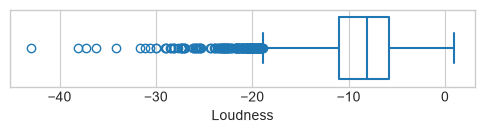

In [346]:
plt.figure(figsize=(6,1))
sns.boxplot(data = df,x ="Loudness", fill = False)



<Axes: xlabel='Valence'>

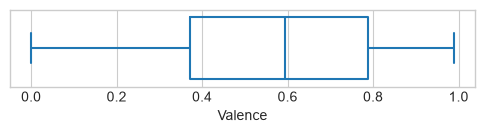

In [347]:
plt.figure(figsize=(6,1))
sns.boxplot(data = df,x ="Valence", fill = False)


## Variable de años en categorias

In [348]:
df["Yearcat"] = pd.cut(
    df["Year"],
    bins=[1969,1979, 1990, 1999, 2015],
    labels=["1970-1979", "1980-1990", "1991-2000", "2000-2015"]
)

### Creamos una nueva categoría de géneros


Por un lado tendremos la categoría metal. Por el otro tenemos al Pop y a la música de hoy en dia


In [349]:

df["Genre2"] = np.select(
    [
        df["Genre"] == "Metal",
        df["Genre"].isin(["Pop", "Today"]),
        
    ],
    [
        "Metal",
        "Pop/Today",
    ],
    default="Resto de géneros"
)


## Variables categoricas

In [350]:
df["Time_Signature"] = df["Time_Signature"].astype(str)
df["Key"] = df["Key"].astype(str)
df["Mode_ascat"] = df["Mode"].astype(str)

## Pasar las variables de la API de Spoty a escala 100
Las variabels de la API de spoty están pensandas para una maquina.
Para que sean más legible para los humanos lo multiplicaremos por 100.
Asi mismo nos da el tiempo en milisegundos. Por ello multiplicamos por mil y dividimos por 60. Así tenemos el tiempo en inteligibles minutos

In [351]:
#df = df[df["Genre"].isin(["Metal", "Punk","Alt. Rock","Rock"])]
#df = df[df["Genre"].isin(["Metal"])]

df["Duration"] = (df["Duration"]/1000) /60


df["Valence"] = df["Valence"] *100
df["Energy"] = df["Energy"] *100
df["Danceability"] = df["Danceability"] *100
df["Speechiness"] = df["Speechiness"] *100
df["Acousticness"] = df["Acousticness"] *100
df["Instrumentalness"] = df["Instrumentalness"] *100
df["Liveness"] = df["Liveness"] *100



In [352]:
df["Popucat"] = pd.cut(
    df["Popularity"],
    bins=[0, 49, 80, 101],
    labels=["0-49", "50-79", "80-100"])

## Inciamos lo descriptivo
### Mapa mediana variables api spoty

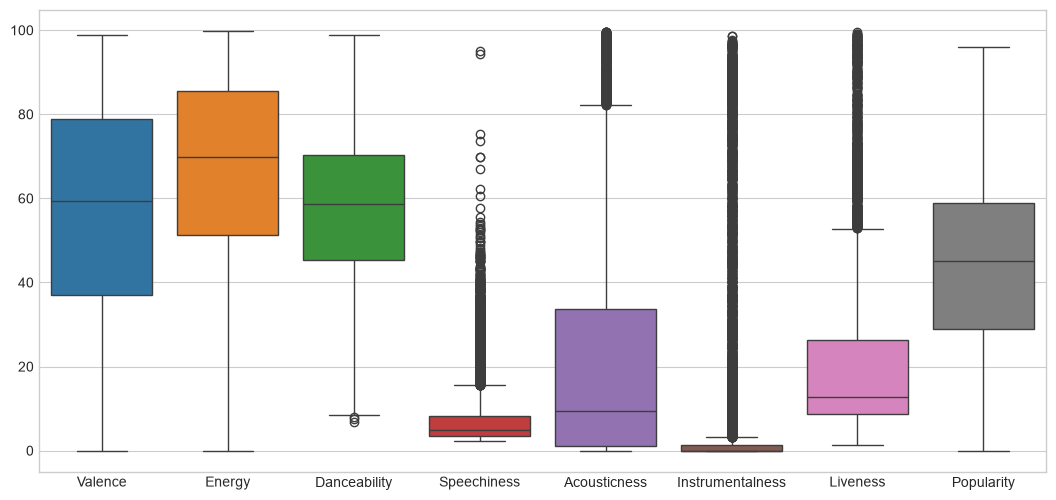

In [353]:
plt.figure(figsize=(13, 6))  # (ancho, alto) en pulgadas
sns.boxplot(data=df[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]])
plt.show()

<Axes: xlabel='Tempo'>

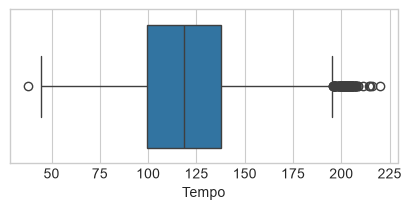

In [354]:
plt.figure(figsize=(5,2))  # (ancho, alto) en pulgadas
sns.boxplot(data = df , x= "Tempo")




In [355]:

plt.figure(figsize=(4, 1))  # (ancho, alto) en pulgadas



<Figure size 400x100 with 0 Axes>

<Figure size 400x100 with 0 Axes>

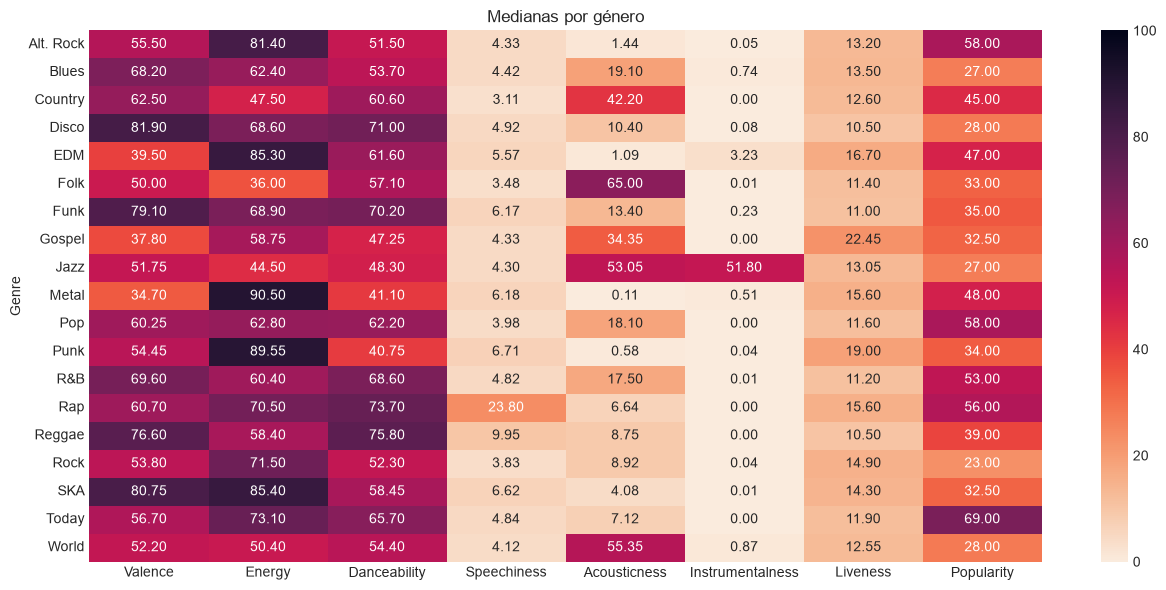

In [468]:
medianas = df.groupby("Genre")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].median()

# Representar mapa de calor
plt.figure(figsize=(13, 6))  # (ancho, alto) en pulgadas
sns.heatmap(
    medianas,
    annot=True,
    cmap= "rocket_r",
    fmt='.2f',
    linewidths=0,
    vmin= 0,
    vmax=100,
    center=50
)
plt.title("Medianas por género")
plt.tight_layout()


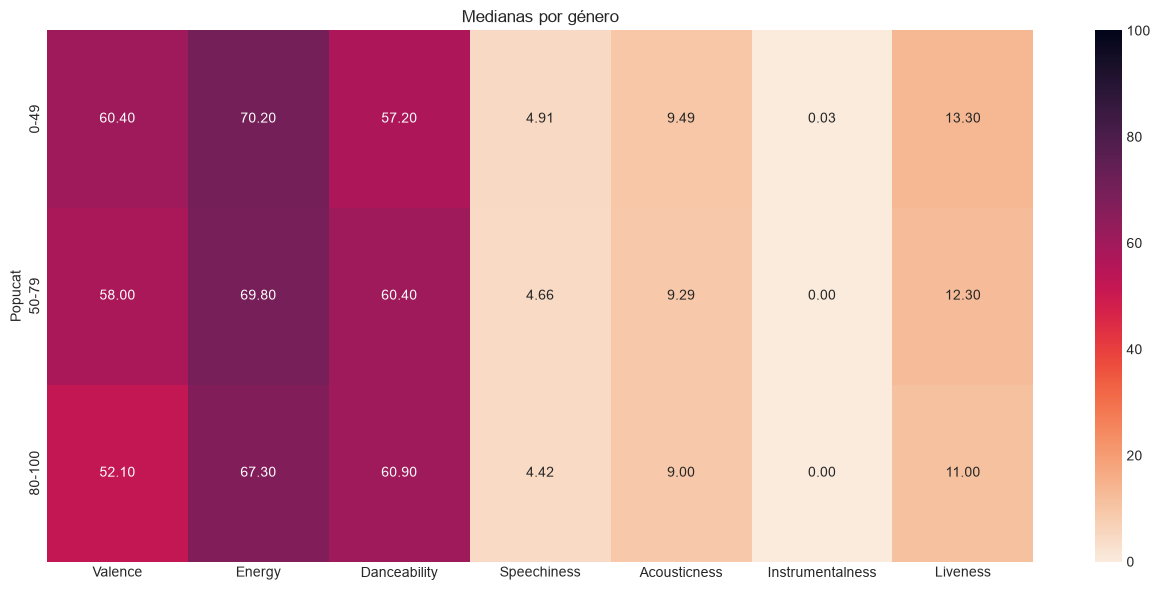

In [357]:
medianas = df.groupby("Popucat")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness"]].median()

# Representar mapa de calor
plt.figure(figsize=(13, 6))  # (ancho, alto) en pulgadas
sns.heatmap(
    medianas,
    annot=True,
    cmap= "rocket_r",
    fmt='.2f',
    linewidths=0,
    vmin= 0,
    vmax=100,
    center=50
)
plt.title("Medianas por género")
plt.tight_layout()


La calve de la canción parece no afectar a los criterios de la API de Spotify

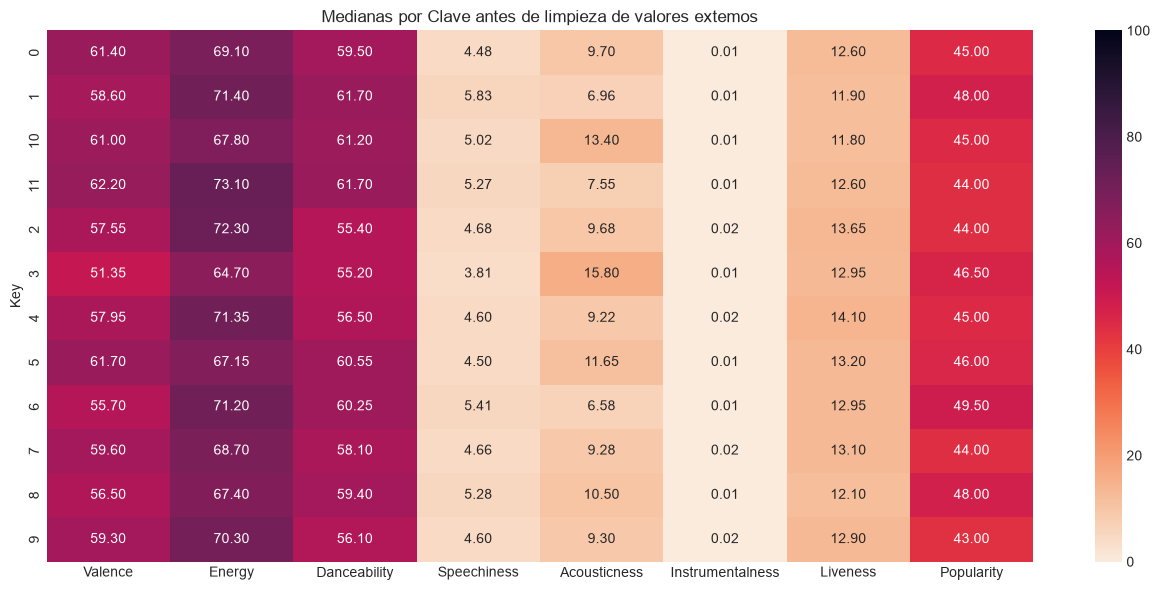

In [358]:
medianas = df.groupby("Key")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].median()

# Representar mapa de calor
plt.figure(figsize=(13, 6))  # (ancho, alto) en pulgadas
sns.heatmap(
    medianas,
    annot=True,
    cmap= "rocket_r",
    fmt='.2f',
    linewidths=0,
    vmin= 0,
    vmax=100,
    center=50
)
plt.title("Medianas por Clave antes de limpieza de valores extemos")
plt.tight_layout()
plt.show()

El modo no parece incidir en estos criterios

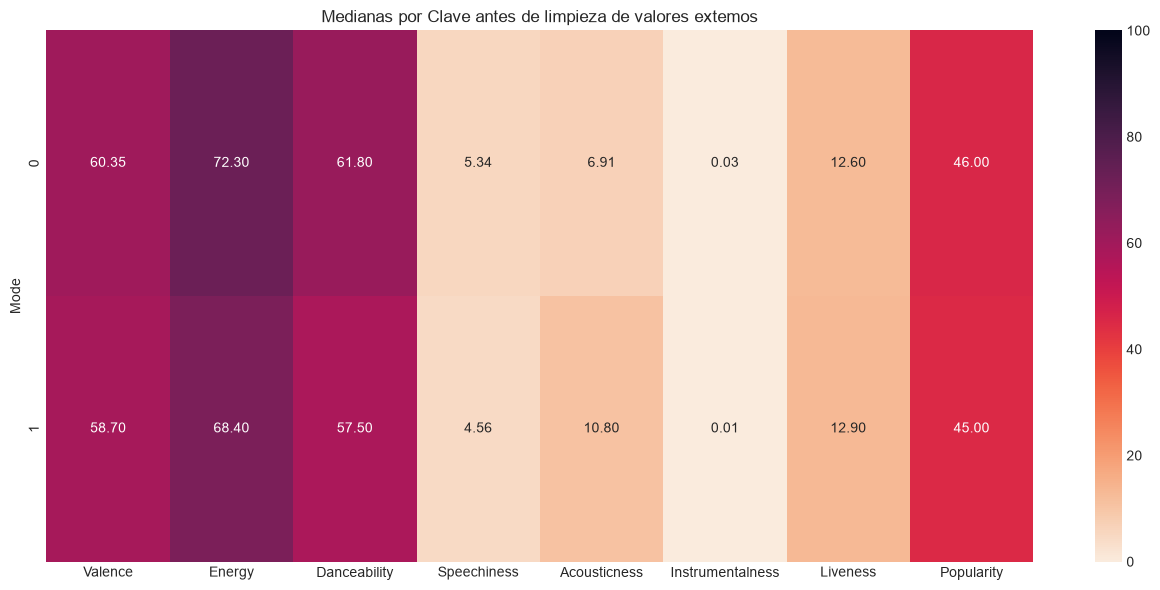

In [359]:
medianas = df.groupby("Mode")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].median()

# Representar mapa de calor
plt.figure(figsize=(13, 6))  # (ancho, alto) en pulgadas
sns.heatmap(
    medianas,
    annot=True,
    cmap= "rocket_r",
    fmt='.2f',
    linewidths=0,
    vmin= 0,
    vmax=100,
    center=50
)
plt.title("Medianas por Clave antes de limpieza de valores extemos")
plt.tight_layout()
plt.show()

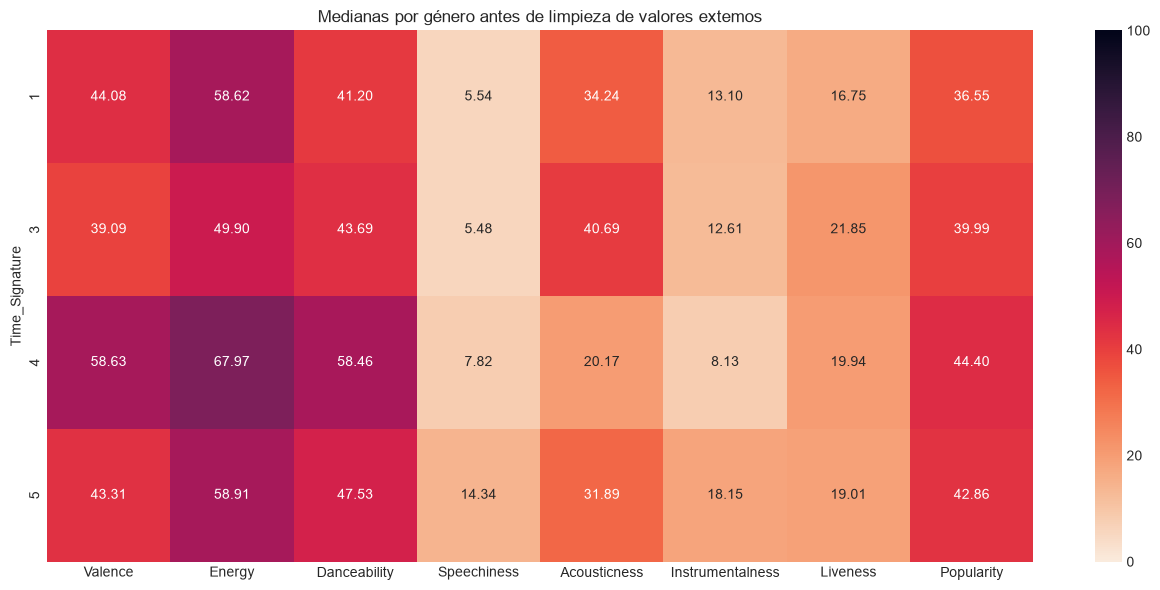

In [360]:
medianas = df.groupby("Time_Signature")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].mean()
# Representar mapa de calor
plt.figure(figsize=(13, 6))  # (ancho, alto) en pulgadas
sns.heatmap(
    medianas,
    annot=True,
    cmap= "rocket_r",
    fmt='.2f',
    linewidths=0,
    vmin= 0,
    vmax=100,
    center=50
)
plt.title("Medianas por género antes de limpieza de valores extemos")
plt.tight_layout()
plt.show()

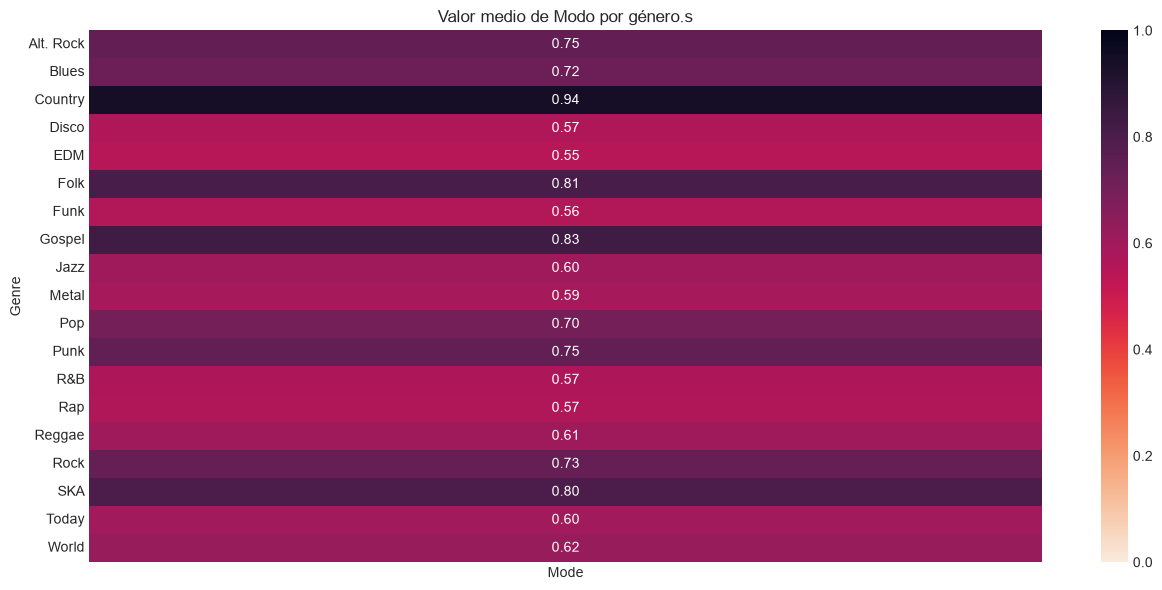

In [361]:
medianas = df.groupby("Genre")[["Mode"]].mean()

# Representar mapa de calor
plt.figure(figsize=(13, 6))  # (ancho, alto) en pulgadas
sns.heatmap(
    medianas,
    annot=True,
    cmap= "rocket_r",
    fmt='.2f',
    linewidths=0,
    vmin= 0,
    vmax=1,
    center=0.5
)
plt.title("Valor medio de Modo por género.s")
plt.tight_layout()
plt.show()

### Quitar valores extremos

In [362]:

#df = df[df["Duration"] < 10]
#df = df[df["Tempo"] > 50]
#df = df[df["Loudness"] > -15]
#df = df[df["Energy"] > 20]
#df = df[df["Instrumentalness"] < 1]
#df = df[df["Speechiness"] < 20]
#df = df[df["Liveness"] < 60]

df.info()



<class 'pandas.DataFrame'>
Index: 10104 entries, 0 to 15149
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   Track             10104 non-null  str     
 1   Artist            10104 non-null  str     
 2   Year              10104 non-null  int64   
 3   Duration          10104 non-null  float64 
 4   Time_Signature    10104 non-null  str     
 5   Danceability      10104 non-null  float64 
 6   Energy            10104 non-null  float64 
 7   Key               10104 non-null  str     
 8   Loudness          10104 non-null  float64 
 9   Mode              10104 non-null  int64   
 10  Speechiness       10104 non-null  float64 
 11  Acousticness      10104 non-null  float64 
 12  Instrumentalness  10104 non-null  float64 
 13  Liveness          10104 non-null  float64 
 14  Valence           10104 non-null  float64 
 15  Tempo             10104 non-null  float64 
 16  Popularity        10104 non-null  int6

## Matriz de correlaciones

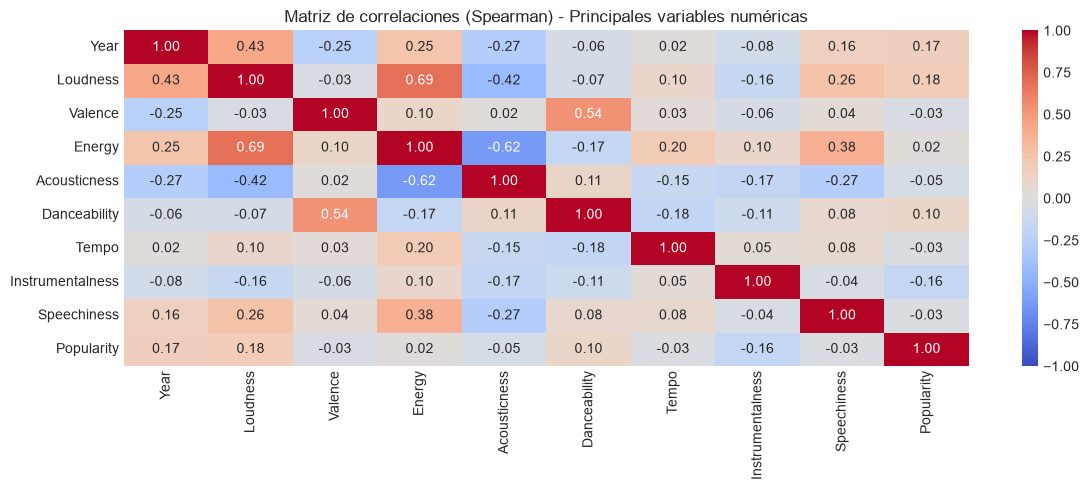

In [363]:
variables = [
    "Year",
    "Loudness",
    "Valence",
    "Energy",
    "Acousticness",
    "Danceability",
    "Tempo",
    "Instrumentalness",
    "Speechiness",
    "Popularity"
   
]

corr = df[variables].corr("spearman")

plt.figure(figsize=(12, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    vmin =-1
)

plt.title("Matriz de correlaciones (Spearman) - Principales variables numéricas")
plt.tight_layout()
plt.show()

### Loudness media a lo largo del tiempo

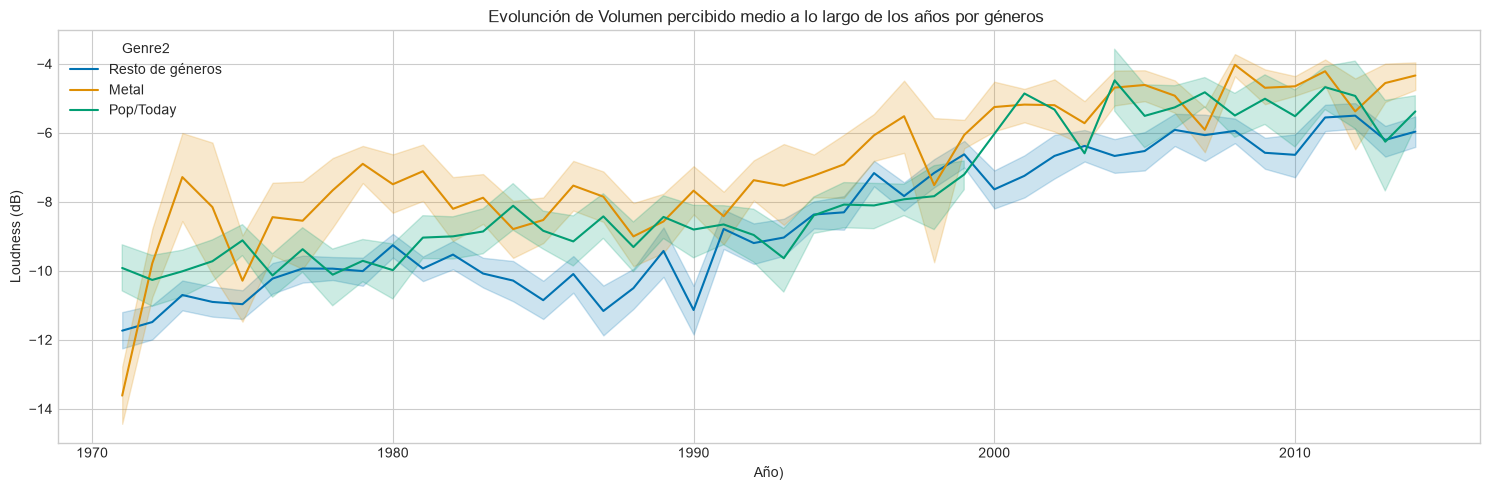

In [ ]:
plt.figure(figsize=(15,5))



sns.lineplot(data = df, x = "Year", y = "Loudness", hue = "Genre2", palette = "colorblind",  errorbar=("ci", 90))
plt.title("Evolunción de Volumen percibido medio a lo largo de los años por géneros ")
plt.xlabel("Año")
plt.ylabel("Loudness (dB)")
plt.tight_layout()
plt.show()

Correlaciones con tiempo significativas

(-25.0, 1.0)

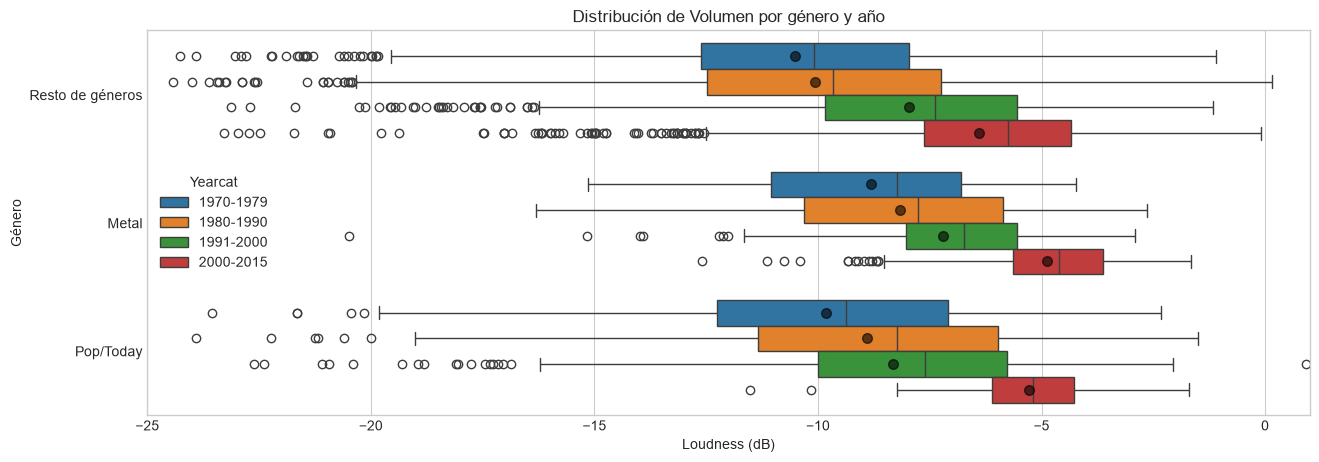

In [450]:
plt.figure(figsize=(15,5))

sns.boxplot(data = df, x = "Loudness", y= "Genre2" , fill = True   ,hue = "Yearcat",showmeans=True,  meanprops={
        "marker": "o",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 7,
        "alpha": 0.6
    }
)

plt.title("Distribución de Volumen por género y año")
plt.xlabel("Loudness (dB)")
plt.ylabel("Género")
plt.xlim(-25, 1)


RuntimeError: No mappable was found to use for colorbar creation. First define a mappable such as an image (with imshow) or a contour set (with contourf).

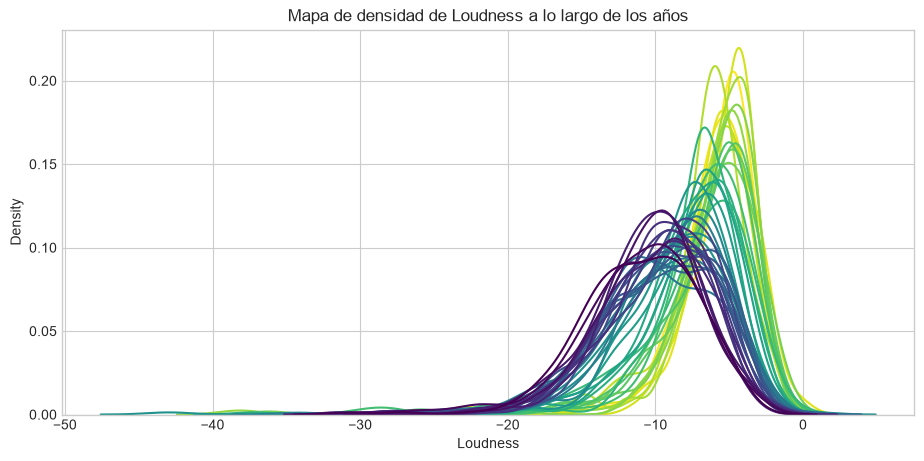

In [ ]:
plt.figure(figsize=(11,5))

sns.kdeplot(
    data=df,
    x="Loudness",
    hue="Year",
    palette="viridis",
    legend=False,
    common_norm=False
)

plt.title("Mapa de densidad de Loudness a lo largo de los años")
plt.xlabel("Loudness (dB)")
plt.ylabel("Densidad")
plt.show()

In [366]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = spearmanr(subset["Loudness"], subset["Year"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
   
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")



Metal: R = 0.563, p-value = 0.0000
SKA: R = 0.462, p-value = 0.0000
Alt. Rock: R = 0.458, p-value = 0.0000
Gospel: R = 0.410, p-value = 0.0000
Reggae: R = 0.392, p-value = 0.0000
Rock: R = 0.357, p-value = 0.0000
Country: R = 0.351, p-value = 0.0000
Blues: R = 0.328, p-value = 0.0000
R&B: R = 0.324, p-value = 0.0000
Rap: R = 0.314, p-value = 0.0000
EDM: R = 0.267, p-value = 0.0000
Punk: R = 0.258, p-value = 0.0000
Pop: R = 0.192, p-value = 0.0000
Disco: R = 0.107, p-value = 0.0066


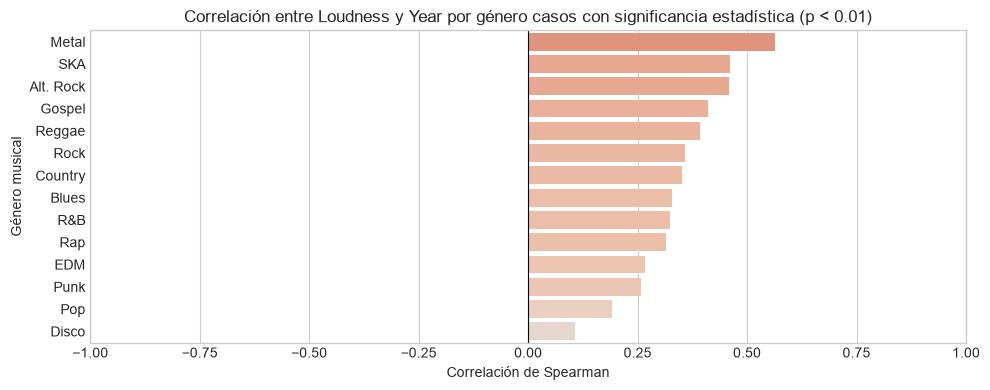

In [367]:


corr_df = pd.DataFrame(resultados, columns=["Género", "R", "p-value"])
corr_df = corr_df.sort_values("R", ascending=False)

plt.figure(figsize=(10, 4))

sns.barplot(
    data=corr_df,
    x="R",
    y="Género",
    hue="R",
    palette="coolwarm",
    hue_norm=(-1, 1),
    dodge=False,
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(-1, 1)
plt.xlabel("Correlación de Spearman")
plt.ylabel("Género musical")
plt.title("Correlación entre Loudness y Year por género casos con significancia estadística (p < 0.01)")

plt.tight_layout()
plt.show()

### Valence media a lo largo del tiempo

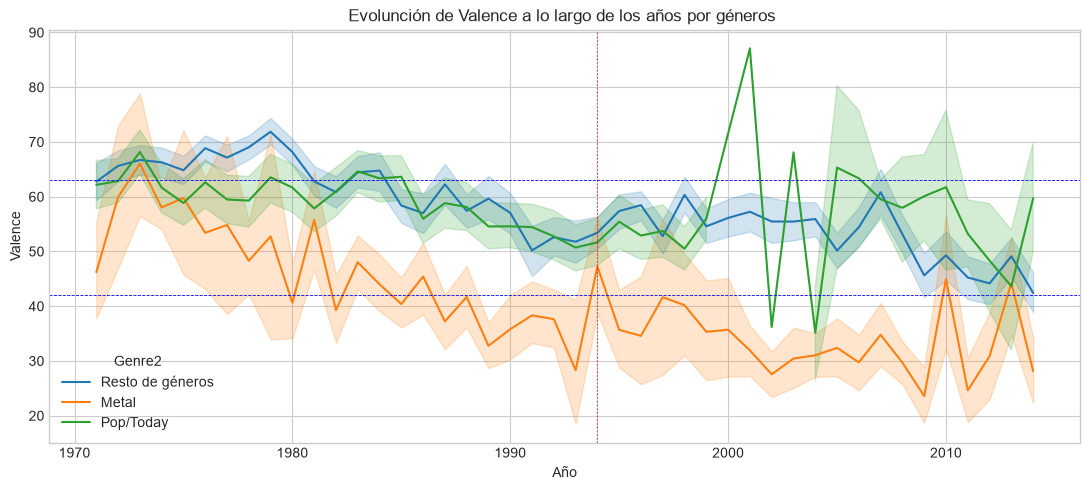

In [452]:

plt.figure(figsize=(11,5))

sns.lineplot(data = df, x = "Year", y = "Valence", hue = "Genre2", errorbar=("ci", 90))
plt.title("Evolunción de Valence a lo largo de los años por géneros ")
plt.tight_layout()
plt.xlabel("Año")
plt.ylabel("Valence")
plt.axvline(x=1994, color='red', linestyle='--', linewidth=0.5)
plt.axhline(y=63, color='blue', linestyle='--', linewidth=0.6)
plt.axhline(y=42, color='blue', linestyle='--', linewidth=0.6)



plt.show()

Text(0, 0.5, 'Densidad')

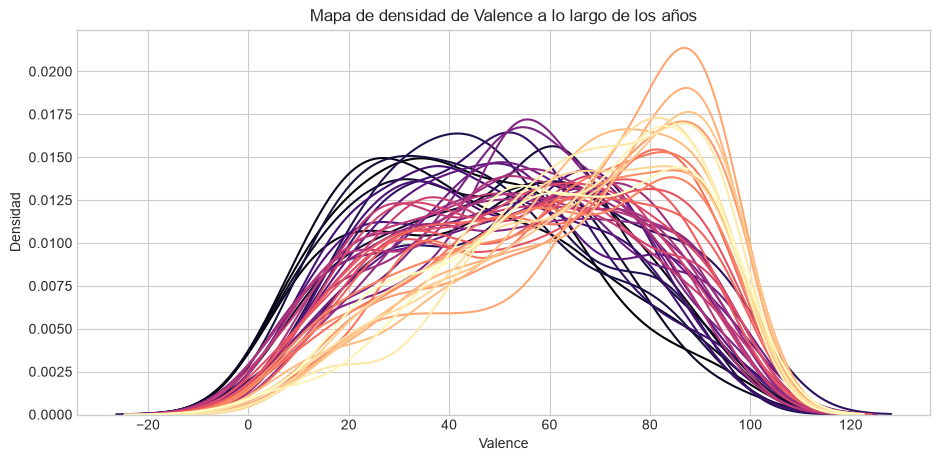

In [453]:
plt.figure(figsize=(11,5))

sns.kdeplot(data= df,x = "Valence", hue="Year", palette="magma_r", legend=False, common_norm=False)
plt.title("Mapa de densidad de Valence a lo largo de los años")
plt.xlabel("Valence")
plt.ylabel("Densidad")

Cambios de valence en funcion del género significagtivos

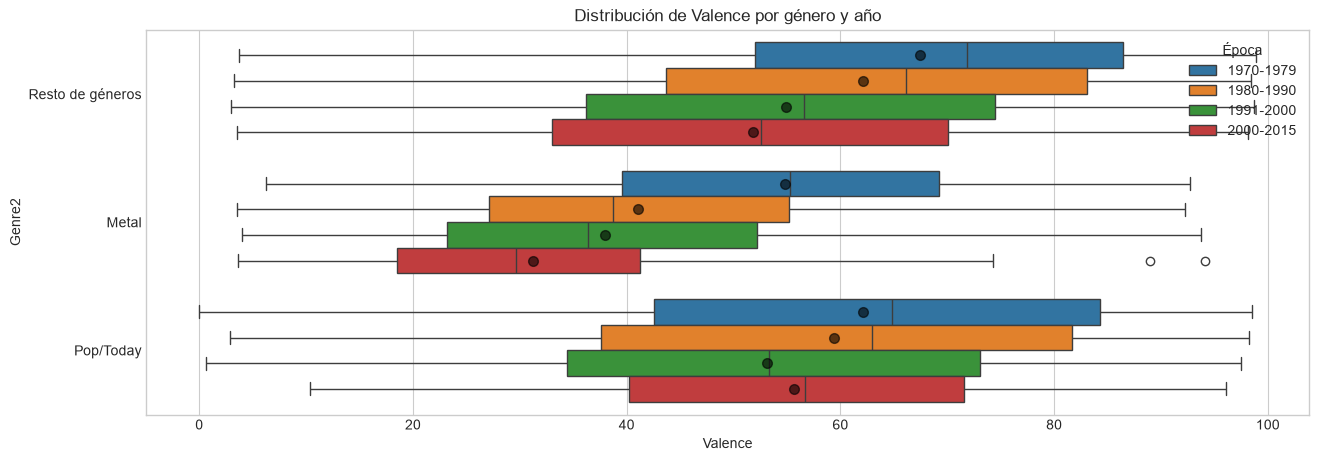

In [369]:
plt.figure(figsize=(15,5))

sns.boxplot(data = df, x = "Valence", y= "Genre2" , fill = True,hue = "Yearcat", showmeans=True,  meanprops={
        "marker": "o",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 7,
        "alpha": 0.6
    })
plt.title("Distribución de Valence por género y año")
plt.legend(title="Época", loc="upper right")

En el caso del metal se observa una pequeña alza de la postividad de las canciones entre poco depspues del año 2000 y mediados de la década. Esto concuerda con un periodo sociohistorico muy concreto. El periodo entre el 11-S y el comienzo del hastío con la guera de Irak.

Para analizar como afecto este fénomeno a la producción músical analizaremos dos géneros contrapuestos el Country y el Punkk

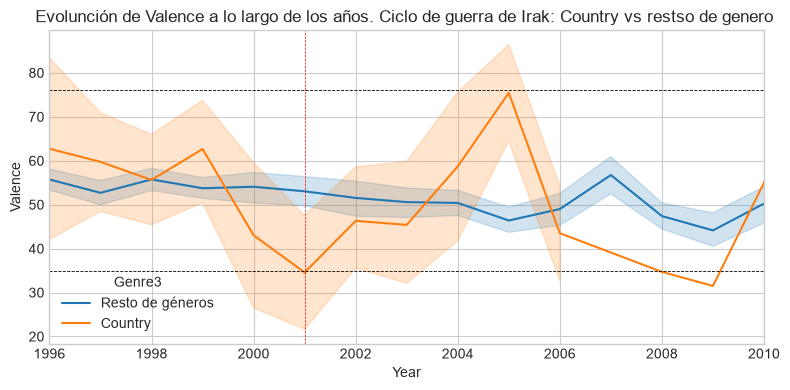

In [370]:

df["Genre3"] = np.select(
    [
        df["Genre"] == "Country"


    
    ],
    [
        "Country"
      

    ],
    default="Resto de géneros"
)
plt.figure(figsize=(8,4))
sns.lineplot(data = df, x = "Year", y = "Valence", hue = "Genre3", errorbar=("ci", 90))
plt.xlim(1996, 2010)
plt.title("Evolunción de Valence a lo largo de los años. Ciclo de guerra de Irak: Country vs restso de genero ")
plt.tight_layout()
plt.axvline(x=2001, color='red', linestyle='--', linewidth=0.5)
plt.axhline(y=35, color='black', linestyle='--', linewidth=0.6)
plt.axhline(y=76, color='black', linestyle='--', linewidth=0.6)


plt.show()

In [371]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = spearmanr(subset["Valence"], subset["Year"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Country: R = -0.140, p-value = 0.0026
Pop: R = -0.148, p-value = 0.0000
Rock: R = -0.153, p-value = 0.0001
Gospel: R = -0.233, p-value = 0.0004
Rap: R = -0.277, p-value = 0.0000
Alt. Rock: R = -0.278, p-value = 0.0000
Metal: R = -0.307, p-value = 0.0000
R&B: R = -0.336, p-value = 0.0000


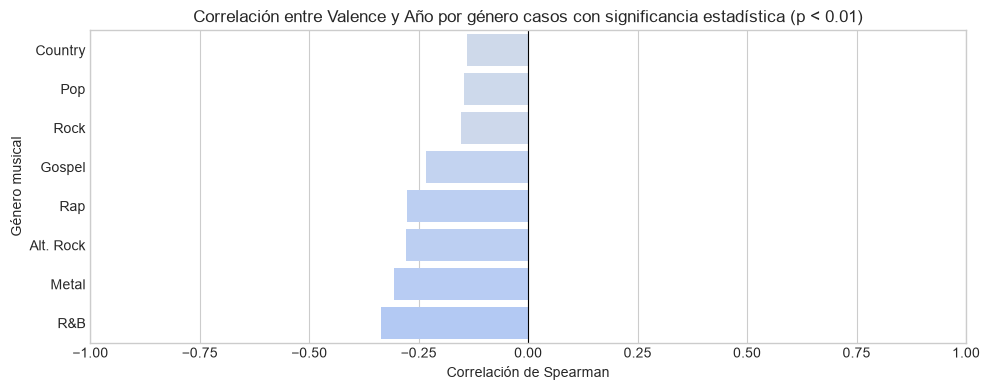

In [372]:
corr_df = pd.DataFrame(resultados, columns=["Género", "R", "p-value"])
corr_df = corr_df.sort_values("R", ascending=False)

plt.figure(figsize=(10, 4))

sns.barplot(
    data=corr_df,
    x="R",
    y="Género",
    hue="R",
    palette="coolwarm",
    hue_norm=(-1, 1),
    dodge=False,
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(-1, 1)
plt.xlabel("Correlación de Spearman")
plt.ylabel("Género musical")
plt.title("Correlación entre Valence y Año por género casos con significancia estadística (p < 0.01)")

plt.tight_layout()
plt.show()

Cambios en el tiempo: Energía

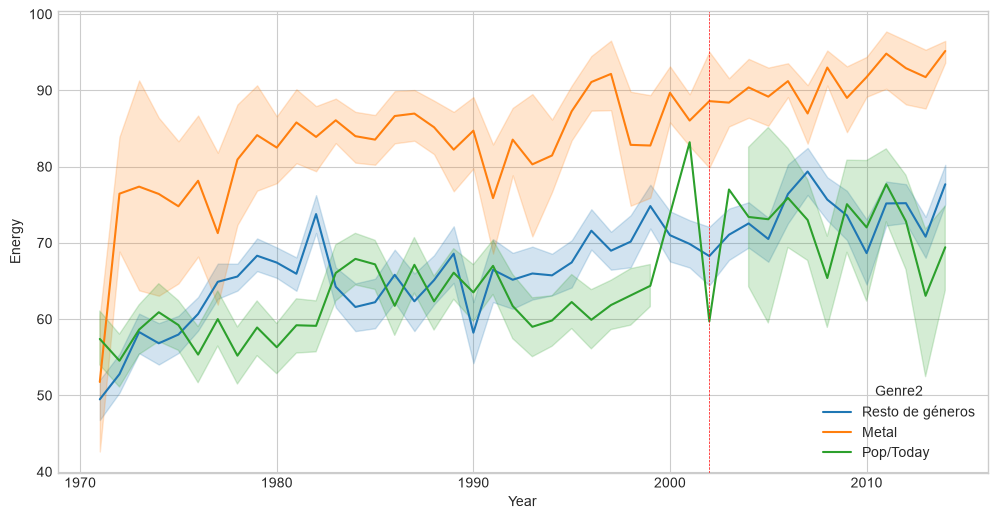

In [373]:
plt.figure(figsize=(12,6))

sns.lineplot(data = df, x = "Year", y = "Energy", hue = "Genre2", errorbar=("ci", 90))
plt.axvline(x=2002, color='red', linestyle='--', linewidth=0.5)




Text(0, 0.5, 'Densidad')

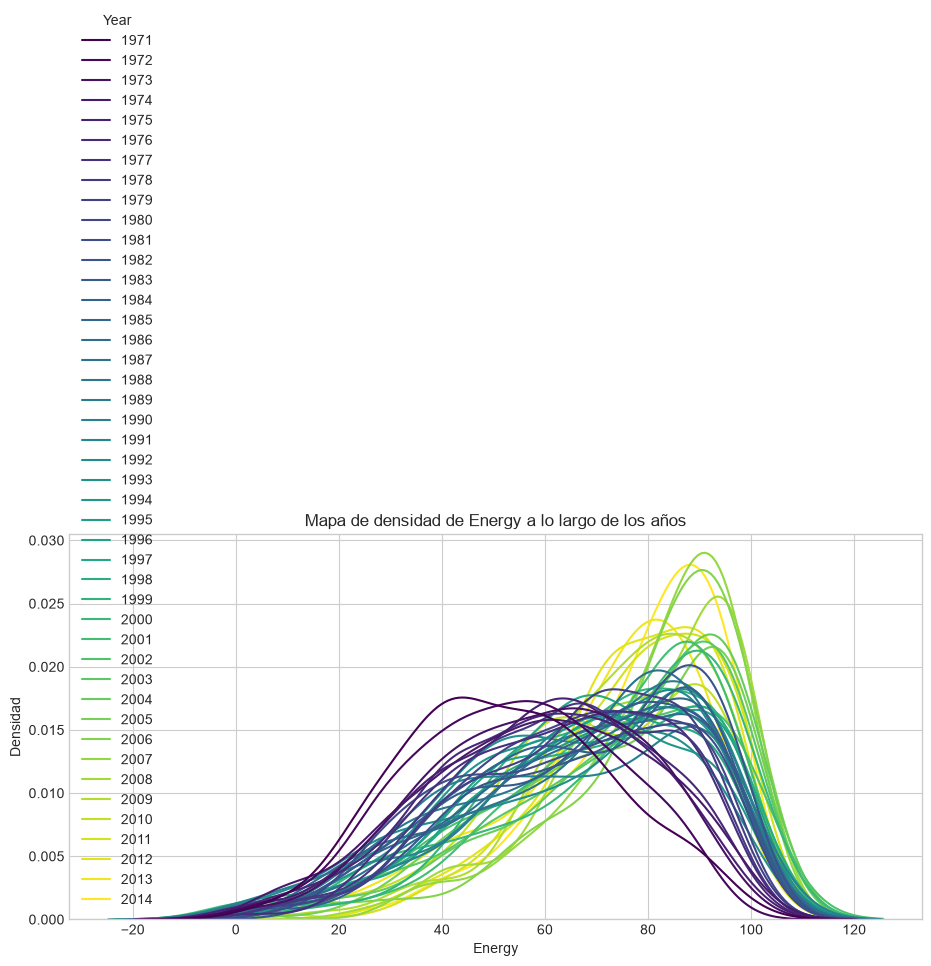

In [464]:
plt.figure(figsize=(11,5))

sns.kdeplot(data= df,x = "Energy", hue="Year", palette="viridis", legend=True, common_norm=False)
plt.title("Mapa de densidad de Energy a lo largo de los años")
plt.xlabel("Energy")
plt.ylabel("Densidad")

Text(0.5, 1.0, 'Distribución de Energy por géneros')

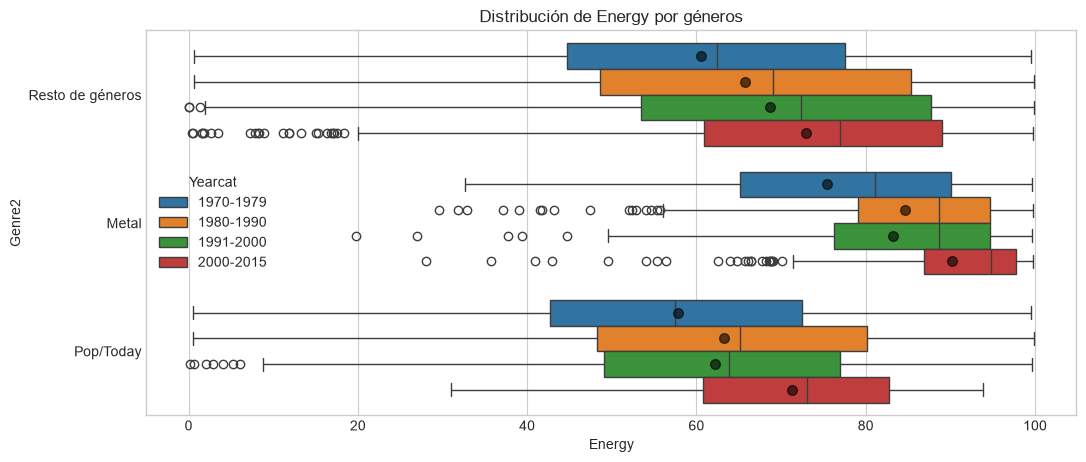

In [374]:
plt.figure(figsize=(12,5))


sns.boxplot(data = df, x = "Energy", y= "Genre2" ,hue = "Yearcat",showmeans=True,  meanprops={
        "marker": "o",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 7,
        "alpha": 0.6
    })
plt.title("Distribución de Energy por géneros")


In [375]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = spearmanr(subset["Energy"], subset["Year"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

SKA: R = 0.368, p-value = 0.0000
Reggae: R = 0.363, p-value = 0.0000
Metal: R = 0.323, p-value = 0.0000
Country: R = 0.283, p-value = 0.0000
Punk: R = 0.227, p-value = 0.0000
Alt. Rock: R = 0.167, p-value = 0.0000
Rock: R = 0.155, p-value = 0.0001
Disco: R = 0.110, p-value = 0.0054
Pop: R = 0.100, p-value = 0.0000


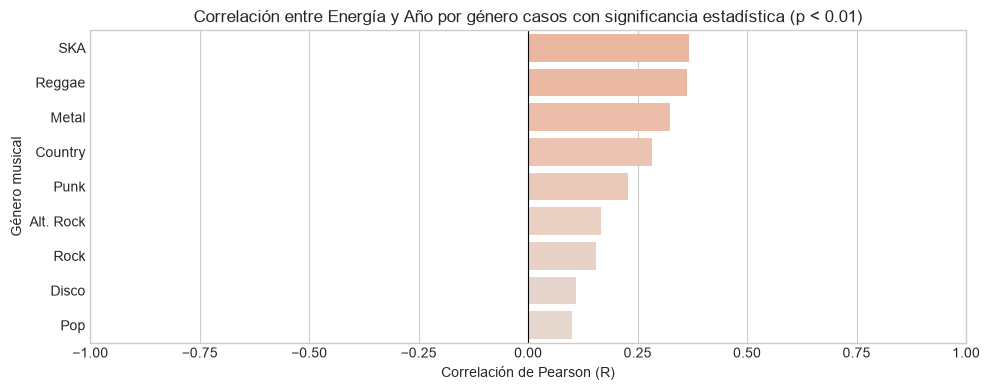

In [376]:
corr_df = pd.DataFrame(resultados, columns=["Género", "R", "p-value"])
corr_df = corr_df.sort_values("R", ascending=False)

plt.figure(figsize=(10, 4))

sns.barplot(
    data=corr_df,
    x="R",
    y="Género",
    hue="R",
    palette="coolwarm",
    hue_norm=(-1, 1),
    dodge=False,
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(-1, 1)
plt.xlabel("Correlación de Pearson (R)")
plt.ylabel("Género musical")
plt.title("Correlación entre Energía y Año por género casos con significancia estadística (p < 0.01)")

plt.tight_layout()
plt.show()

Evolución: Acustica 

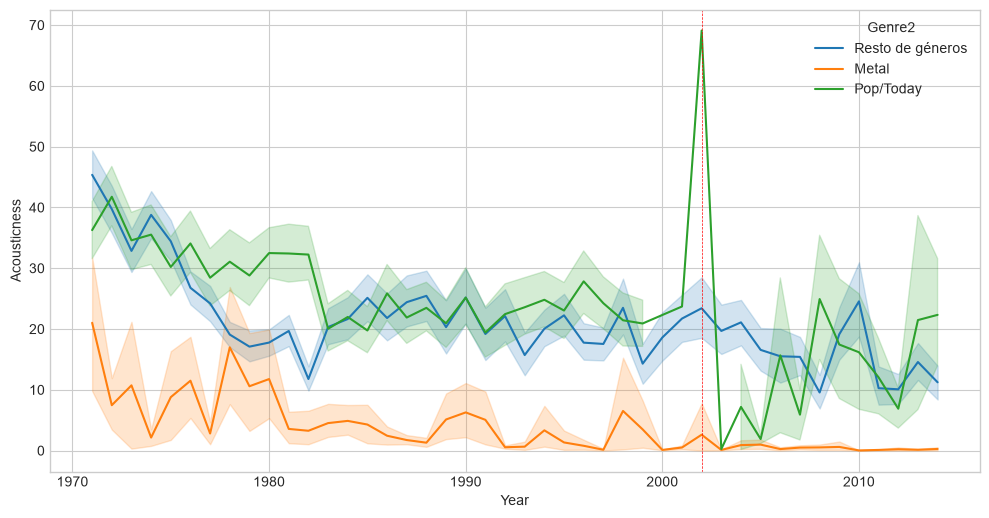

In [377]:
plt.figure(figsize=(12,6))

sns.lineplot(data = df, x = "Year", y = "Acousticness", hue = "Genre2", errorbar=("ci", 90))
plt.axvline(x=2002, color='red', linestyle='--', linewidth=0.5)

Text(0, 0.5, 'Densidad')

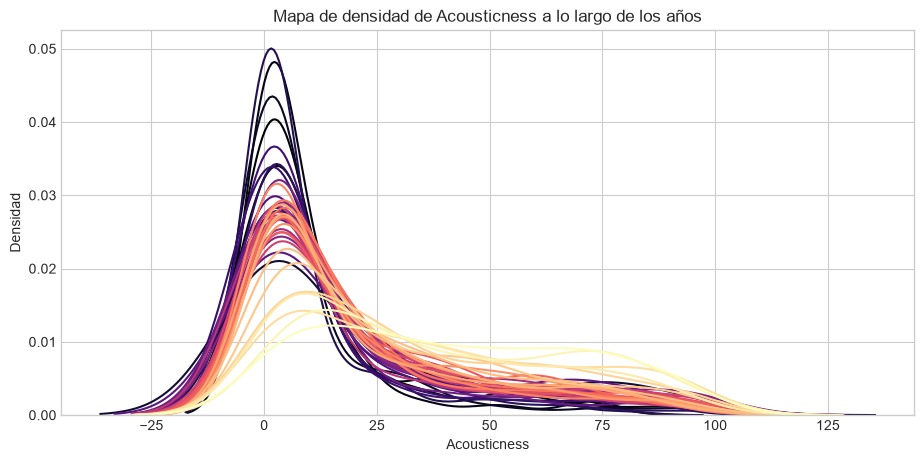

In [455]:
plt.figure(figsize=(11,5))

sns.kdeplot(data= df,x = "Acousticness", hue="Year", palette="magma_r", legend=False, common_norm=False)
plt.title("Mapa de densidad de Acousticness a lo largo de los años")
plt.xlabel("Acousticness")
plt.ylabel("Densidad")

In [378]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = spearmanr(subset["Acousticness"], subset["Year"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Rap: R = 0.118, p-value = 0.0093
R&B: R = -0.153, p-value = 0.0017
Punk: R = -0.168, p-value = 0.0000
Funk: R = -0.186, p-value = 0.0009
Pop: R = -0.190, p-value = 0.0000
Rock: R = -0.230, p-value = 0.0000
Disco: R = -0.240, p-value = 0.0000
Gospel: R = -0.240, p-value = 0.0002
Alt. Rock: R = -0.243, p-value = 0.0000
Country: R = -0.396, p-value = 0.0000
Metal: R = -0.454, p-value = 0.0000


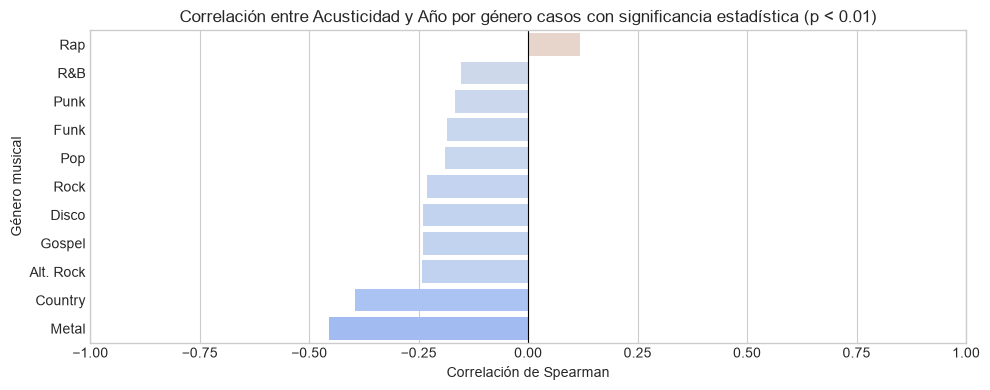

In [379]:
corr_df = pd.DataFrame(resultados, columns=["Género", "R", "p-value"])
corr_df = corr_df.sort_values("R", ascending=False)

plt.figure(figsize=(10, 4))

sns.barplot(
    data=corr_df,
    x="R",
    y="Género",
    hue="R",
    palette="coolwarm",
    hue_norm=(-1, 1),
    dodge=False,
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(-1, 1)
plt.xlabel("Correlación de Spearman")
plt.ylabel("Género musical")
plt.title("Correlación entre Acusticidad y Año por género casos con significancia estadística (p < 0.01)")

plt.tight_layout()
plt.show()

<Axes: xlabel='Acousticness', ylabel='Genre2'>

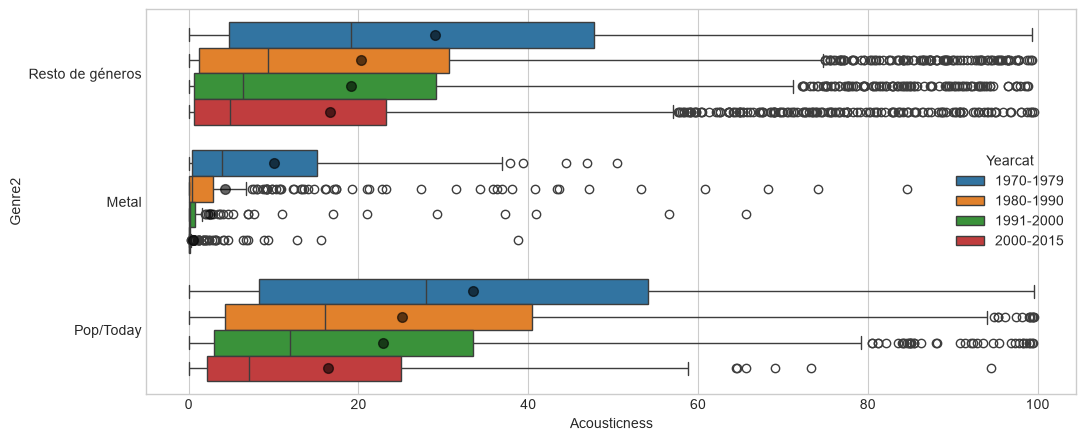

In [380]:
plt.figure(figsize=(12,5))


sns.boxplot(data = df, x = "Acousticness", y= "Genre2" ,hue = "Yearcat",showmeans=True,  meanprops={
        "marker": "o",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 7,
        "alpha": 0.6
    })

Evolucion de Bailabilidad

<Axes: xlabel='Danceability', ylabel='Genre2'>

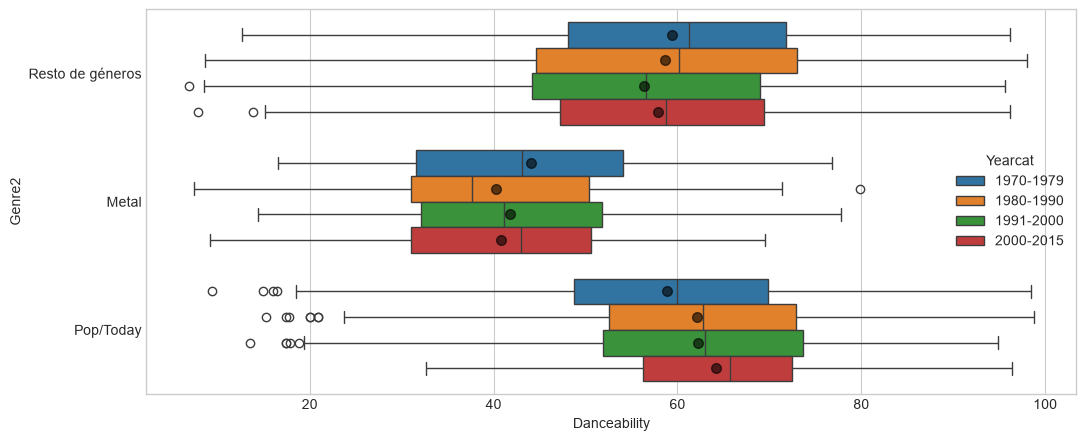

In [381]:
plt.figure(figsize=(12,5))


sns.boxplot(data = df, x = "Danceability", y= "Genre2" ,hue = "Yearcat",showmeans=True,  meanprops={
        "marker": "o",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 7,
        "alpha": 0.6
    })

Text(0, 0.5, 'Densidad')

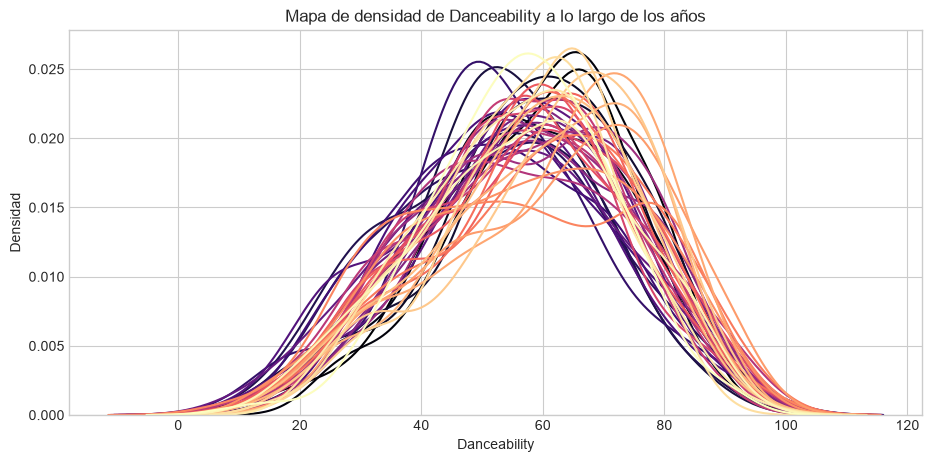

In [456]:
plt.figure(figsize=(11,5))

sns.kdeplot(data= df,x = "Danceability", hue="Year", palette="magma_r", legend=False, common_norm=False)
plt.title("Mapa de densidad de Danceability a lo largo de los años")
plt.xlabel("Danceability")
plt.ylabel("Densidad")

Evolucion del tempo

<Axes: xlabel='Tempo', ylabel='Genre2'>

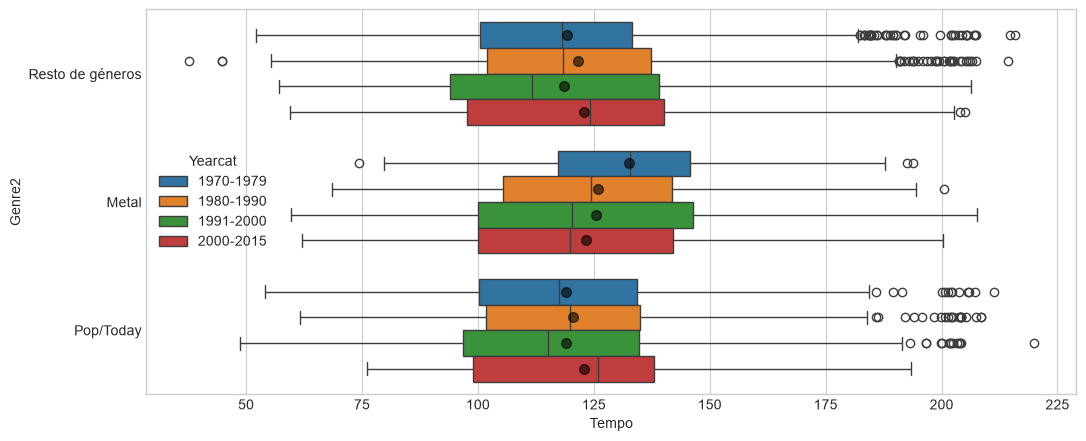

In [382]:
plt.figure(figsize=(12,5))


sns.boxplot(data = df, x = "Tempo", y= "Genre2" ,hue = "Yearcat", fill = True, showmeans=True,  meanprops={
        "marker": "o",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 7,
        "alpha": 0.6
    })

In [383]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = spearmanr(subset["Danceability"], subset["Year"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Disco: R = 0.325, p-value = 0.0000
Funk: R = 0.203, p-value = 0.0003
Pop: R = 0.084, p-value = 0.0000
Reggae: R = -0.189, p-value = 0.0002
SKA: R = -0.273, p-value = 0.0000
Rap: R = -0.326, p-value = 0.0000


Text(0, 0.5, 'Densidad')

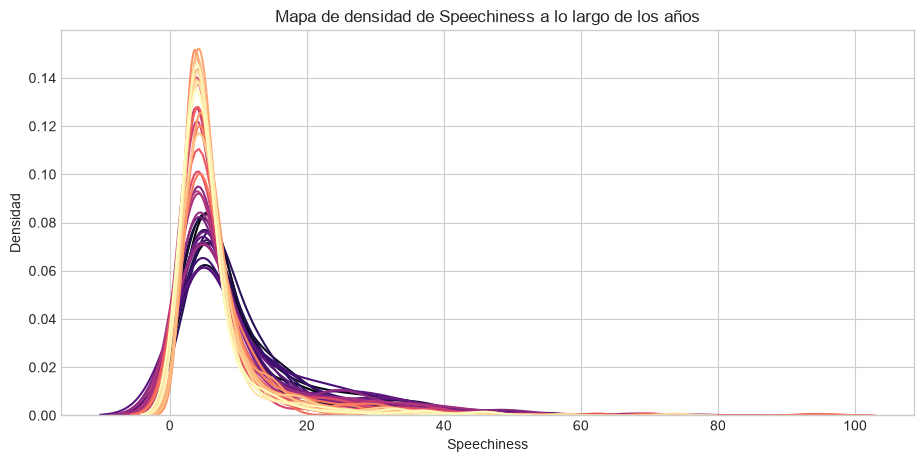

In [457]:
plt.figure(figsize=(11,5))

sns.kdeplot(data= df,x = "Speechiness", hue="Year", palette="magma_r", legend=False, common_norm=False)
plt.title("Mapa de densidad de Speechiness a lo largo de los años")
plt.xlabel("Speechiness")
plt.ylabel("Densidad")

Text(0, 0.5, 'Densidad')

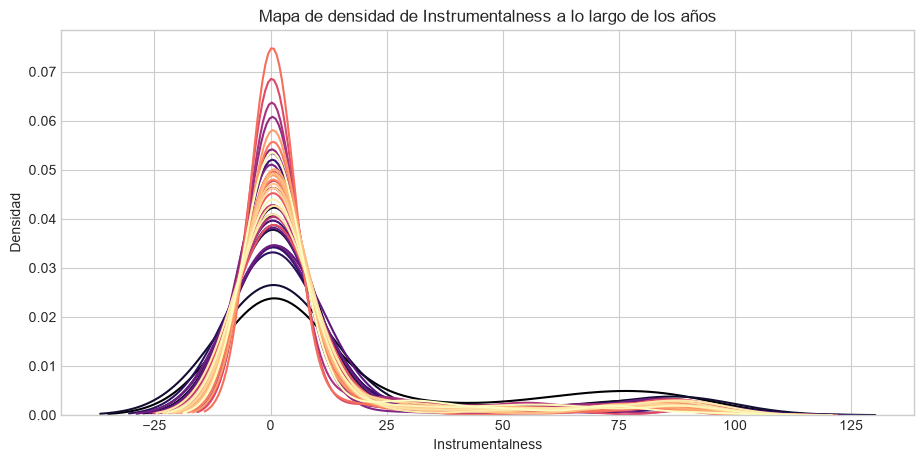

In [458]:
plt.figure(figsize=(11,5))

sns.kdeplot(data= df,x = "Instrumentalness", hue="Year", palette="magma_r", legend=False, common_norm=False)
plt.title("Mapa de densidad de Instrumentalness a lo largo de los años")
plt.xlabel("Instrumentalness")
plt.ylabel("Densidad")

# Popularidad y géneros

Fecha y popularidad por género

In [384]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = spearmanr(subset["Popularity"], subset["Year"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Alt. Rock: R = 0.354, p-value = 0.0000
Gospel: R = 0.311, p-value = 0.0000
Rap: R = 0.286, p-value = 0.0000
Country: R = 0.277, p-value = 0.0000
R&B: R = 0.277, p-value = 0.0000
Reggae: R = 0.254, p-value = 0.0000
Punk: R = 0.245, p-value = 0.0000
Metal: R = 0.102, p-value = 0.0026
Pop: R = 0.101, p-value = 0.0000
Rock: R = -0.231, p-value = 0.0000


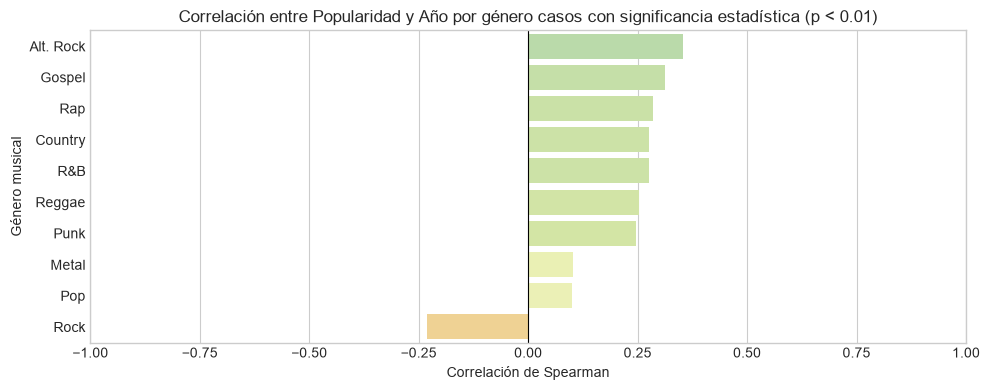

In [385]:
corr_df = pd.DataFrame(resultados, columns=["Género", "R", "p-value"])
corr_df = corr_df.sort_values("R", ascending=False)

plt.figure(figsize=(10, 4))

sns.barplot(
    data=corr_df,
    x="R",
    y="Género",
    hue="R",
    palette="Spectral",
    hue_norm=(-1, 1),
    dodge=False,
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(-1, 1)
plt.xlabel("Correlación de Spearman")
plt.ylabel("Género musical")
plt.title("Correlación entre Popularidad y Año por género casos con significancia estadística (p < 0.01)")

plt.tight_layout()
plt.show()

valence y popularidad por genero 

In [386]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = spearmanr(subset["Popularity"], subset["Valence"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

EDM: R = 0.255, p-value = 0.0000
Punk: R = 0.172, p-value = 0.0000
Metal: R = 0.148, p-value = 0.0000
Alt. Rock: R = -0.107, p-value = 0.0034
Gospel: R = -0.269, p-value = 0.0000


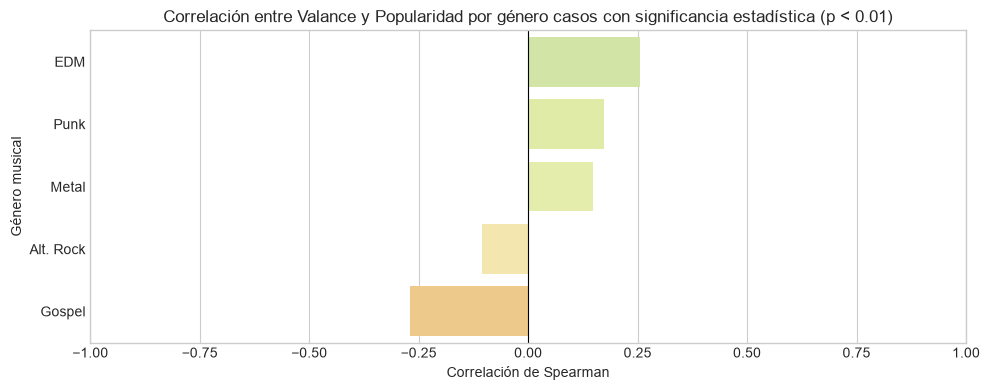

In [387]:
corr_df = pd.DataFrame(resultados, columns=["Género", "R", "p-value"])
corr_df = corr_df.sort_values("R", ascending=False)

plt.figure(figsize=(10, 4))

sns.barplot(
    data=corr_df,
    x="R",
    y="Género",
    hue="R",
    hue_norm=(-1, 1),
    palette="Spectral",
    dodge=False,
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(-1, 1)
plt.xlabel("Correlación de Spearman")
plt.ylabel("Género musical")
plt.title("Correlación entre Valance y Popularidad por género casos con significancia estadística (p < 0.01)")

plt.tight_layout()
plt.show()

loudness y popularidad por género

In [388]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = spearmanr(subset["Popularity"], subset["Loudness"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Alt. Rock: R = 0.245, p-value = 0.0000
Gospel: R = 0.223, p-value = 0.0006
Rap: R = 0.218, p-value = 0.0000
Metal: R = 0.193, p-value = 0.0000
Country: R = 0.180, p-value = 0.0001
Pop: R = 0.177, p-value = 0.0000
SKA: R = 0.176, p-value = 0.0024
Reggae: R = 0.169, p-value = 0.0008


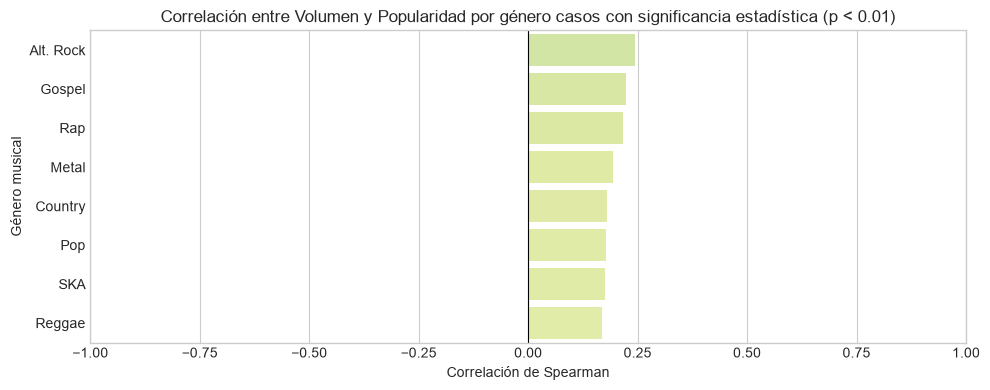

In [389]:
corr_df = pd.DataFrame(resultados, columns=["Género", "R", "p-value"])
corr_df = corr_df.sort_values("R", ascending=False)

plt.figure(figsize=(10, 4))

sns.barplot(
    data=corr_df,
    x="R",
    y="Género",
    hue="R",
    hue_norm=(-1, 1),
    palette="Spectral",
    dodge=False,
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(-1, 1)
plt.xlabel("Correlación de Spearman")
plt.ylabel("Género musical")
plt.title("Correlación entre Volumen y Popularidad por género casos con significancia estadística (p < 0.01)")

plt.tight_layout()
plt.show()

Energy y popularidad por génreo

In [390]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = spearmanr(subset["Popularity"], subset["Energy"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Country: R = 0.202, p-value = 0.0000
Reggae: R = 0.174, p-value = 0.0005
Alt. Rock: R = 0.117, p-value = 0.0013
Pop: R = 0.078, p-value = 0.0001
Funk: R = -0.202, p-value = 0.0003
EDM: R = -0.241, p-value = 0.0000


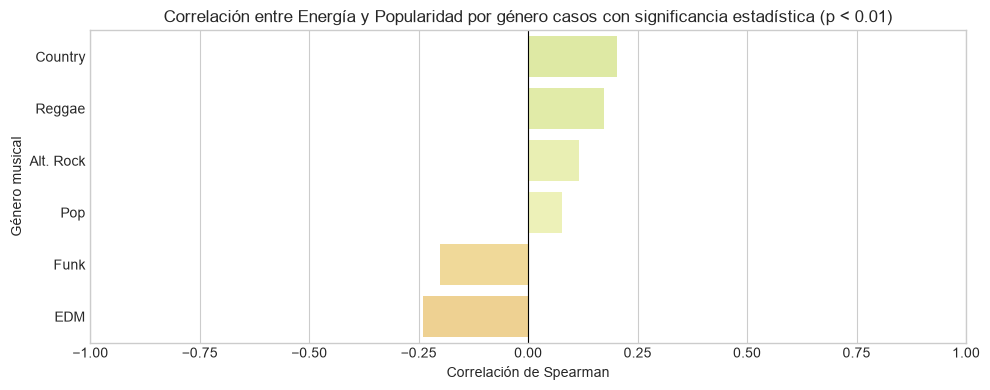

In [391]:
corr_df = pd.DataFrame(resultados, columns=["Género", "R", "p-value"])
corr_df = corr_df.sort_values("R", ascending=False)

plt.figure(figsize=(10, 4))

sns.barplot(
    data=corr_df,
    x="R",
    y="Género",
    hue="R",
    hue_norm=(-1, 1),
    palette="Spectral",
    dodge=False,
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(-1, 1)
plt.xlabel("Correlación de Spearman")
plt.ylabel("Género musical")
plt.title("Correlación entre Energía y Popularidad por género casos con significancia estadística (p < 0.01)")

plt.tight_layout()
plt.show()

Bailabilidad y populariad


In [392]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = spearmanr(subset["Popularity"], subset["Danceability"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Today: R = 0.273, p-value = 0.0061
Jazz: R = 0.206, p-value = 0.0080
Metal: R = 0.205, p-value = 0.0000
Punk: R = 0.166, p-value = 0.0000
EDM: R = 0.159, p-value = 0.0054


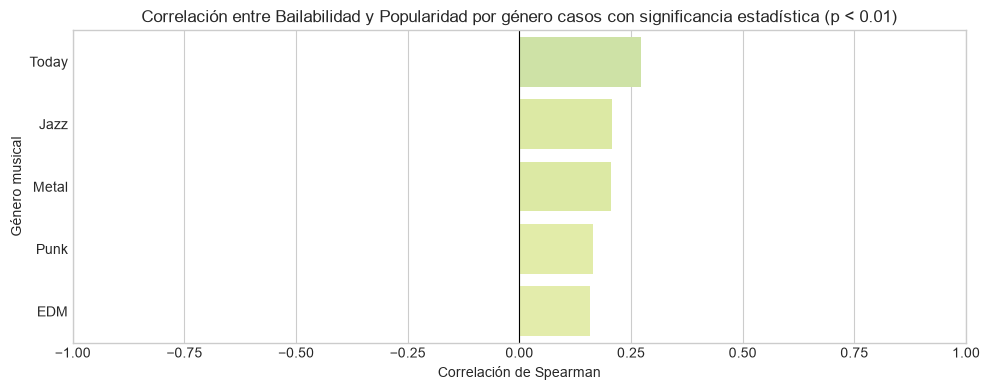

In [393]:
corr_df = pd.DataFrame(resultados, columns=["Género", "R", "p-value"])
corr_df = corr_df.sort_values("R", ascending=False)

plt.figure(figsize=(10, 4))

sns.barplot(
    data=corr_df,
    x="R",
    y="Género",
    hue="R",
    hue_norm=(-1, 1),
    palette="Spectral",
    dodge=False,
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(-1, 1)
plt.xlabel("Correlación de Spearman")
plt.ylabel("Género musical")
plt.title("Correlación entre Bailabilidad y Popularidad por género casos con significancia estadística (p < 0.01)")

plt.tight_layout()
plt.show()

In [394]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = spearmanr(subset["Popularity"], subset["Acousticness"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Funk: R = 0.215, p-value = 0.0001
EDM: R = 0.208, p-value = 0.0003
Pop: R = -0.101, p-value = 0.0000
Alt. Rock: R = -0.186, p-value = 0.0000
Country: R = -0.187, p-value = 0.0001
Blues: R = -0.214, p-value = 0.0020
Gospel: R = -0.273, p-value = 0.0000


In [260]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = spearmanr(subset["Popularity"], subset["Instrumentalness"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Pop: R = -0.072, p-value = 0.0003
Punk: R = -0.105, p-value = 0.0045
Disco: R = -0.111, p-value = 0.0050
Alt. Rock: R = -0.151, p-value = 0.0000
Metal: R = -0.163, p-value = 0.0000
EDM: R = -0.181, p-value = 0.0015
Jazz: R = -0.228, p-value = 0.0033


In [338]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = spearmanr(subset["Popularity"], subset["Speechiness"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Metal: R = -0.108, p-value = 0.0015
Rap: R = -0.192, p-value = 0.0000
Funk: R = -0.232, p-value = 0.0000
